####  Exercise: Linkage Criteria Comparison & Cophenetic Analysis
In this exercise, you will implement a comparison loop across all four linkage methods (`ward`, `complete`, `average`, `single`), compute their Cophenetic Correlation Coefficients, plot four side-by-side dendrograms, and evaluate Silhouette scores. Complete all `TODO` sections.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, cophenet, dendrogram
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

## 1. Load Data & Prepare Pairwise Distance Matrix

In [3]:
data_path = Path("./dataset/hierarchical_sample_data.csv")
df = pd.read_csv(data_path)
features = ['feature_1', 'feature_2', 'feature_3', 'feature_4']
X = df[features]

# Scale features
X_scaled = StandardScaler().fit_transform(X)

# TODO 1: Calculate condensed pairwise Euclidean distances using pdist()
pairwise_dists = pdist(X_scaled)
print("PDist: ", pairwise_dists)

PDist:  [2.87911503 2.57775575 2.32859673 ... 2.41726171 3.829245   3.15701437]


## 2. Compare Linkage Criteria in a Loop

[[3.90000000e+01 6.00000000e+01 1.50040102e-01 2.00000000e+00]
 [3.30000000e+01 4.60000000e+01 3.31379025e-01 2.00000000e+00]
 [6.70000000e+01 9.30000000e+01 3.48120646e-01 2.00000000e+00]
 [2.60000000e+01 8.90000000e+01 4.03903253e-01 2.00000000e+00]
 [1.00000000e+00 3.40000000e+01 4.11337607e-01 2.00000000e+00]
 [5.00000000e+01 5.90000000e+01 4.20763367e-01 2.00000000e+00]
 [1.10000000e+01 9.90000000e+01 4.51768944e-01 2.00000000e+00]
 [3.00000000e+00 8.00000000e+01 4.65914524e-01 2.00000000e+00]
 [3.20000000e+01 9.60000000e+01 5.13717872e-01 2.00000000e+00]
 [2.00000000e+00 5.20000000e+01 5.40139835e-01 2.00000000e+00]
 [2.10000000e+01 4.30000000e+01 5.42787292e-01 2.00000000e+00]
 [1.50000000e+01 7.30000000e+01 5.58894796e-01 2.00000000e+00]
 [4.90000000e+01 7.50000000e+01 5.72259969e-01 2.00000000e+00]
 [4.80000000e+01 5.30000000e+01 5.80476406e-01 2.00000000e+00]
 [6.90000000e+01 8.10000000e+01 5.92211160e-01 2.00000000e+00]
 [1.90000000e+01 2.00000000e+01 5.94353020e-01 2.000000

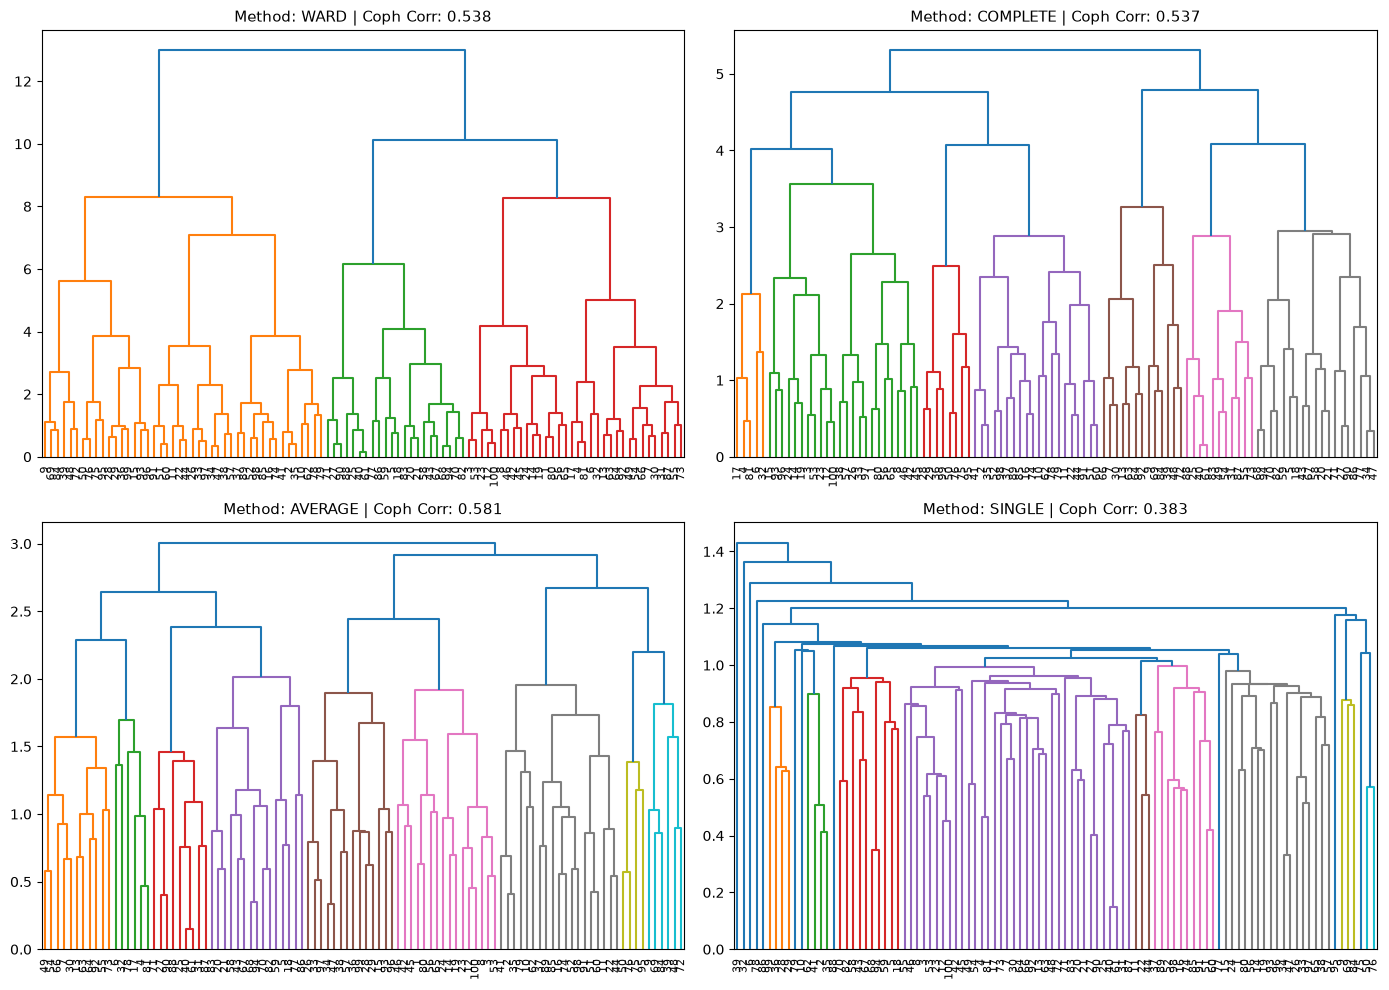

          coph_corr  silhouette
ward       0.538403    0.190519
complete   0.537199    0.142292
average    0.581335    0.205160
single     0.382713    0.021357


In [5]:
linkage_methods = ['ward', 'complete', 'average', 'single']
results = {}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, method in enumerate(linkage_methods):
    # TODO 2: Compute hierarchical linkage matrix Z using linkage()
    Z = linkage(X_scaled,method=method)
    print(Z)
    
    # TODO 3: Calculate Cophenetic Correlation Coefficient using cophenet()
    
    coph_corr, _  = cophenet(Z,pairwise_dists)
    print("Coph_corr: ", coph_corr)
    
    # TODO 4: Fit AgglomerativeClustering with n_clusters=3 and current linkage method
    # Calculate silhouette score on X_scaled
    model = AgglomerativeClustering(n_clusters=3,metric='euclidean',linkage=method)
    
    labels = model.fit_predict(X_scaled)
    # sil_score = 0.0
    sil_score = silhouette_score(X_scaled, labels)
    print("Silhouette Score:", sil_score)
    
    results[method] = {'coph_corr': coph_corr, 'silhouette': sil_score}
    
    # Plot dendrogram
    dendrogram(Z, ax=axes[idx], labels=df['sample_id'].values, leaf_font_size=8)
    axes[idx].set_title(f"Method: {method.upper()} | Coph Corr: {coph_corr:.3f}", fontsize=11)

plt.tight_layout()
plt.show()

# Display summary table
summary_df = pd.DataFrame(results).T
print(summary_df)